# E204 · Adaptive layer allocation

**Can label-free signals tell us how much of the encoder to update?**

| Completed | Stage A · Reused branches | Stage B · Expanded branches | Stage C · Validation |
| --- | --- | --- | --- |
| Six source seeds | 12 states, 144 branches | 48 states, 576 branches | Nested whole-seed holdouts |

- **The opportunity was small.** In Stage B the semantic oracle gained **+0.105 pp** over the best diagnostic fixed action on the average of five linear probes. The oracle uses labels and separate counterfactual draws for diagnosis.
- **The simplest shift rule often reduced to a fixed choice.** For current-regime retrieval it picked Late 4 in all 72 scored cases. Its result does not establish a benefit from responding to shifts.
- **No predictor passed the development gate.** Layer health showed a possible LiDAR benefit. Update-aware retrieval beat its fixed baseline descriptively, while its gain over the cheap context model remained uncertain. The study ended after branch validation.

In [ ]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt

RESULTS = Path('C:/CAFL-E/analysis/2026-11-09-one-step-mpc/o3-simsiam-control/e204')
sys.path.insert(0, str(RESULTS.parents[1]))
from e204_notebook import load_results, semantic_comparison, semantic_detail, predictor_comparison

stage_a, stage_b, predictors = load_results(RESULTS)

def show_plot(figure):
    display(figure)
    plt.close(figure)


## What the branches test

From each checkpoint, all four actions ran for **32 minibatches** on the same incoming data and three paired draws. Skip takes no training step. Late 4 and Late 8 train the last four or eight encoder blocks plus the heads. Full trains the whole encoder plus the heads. The base learning rate was 3 × 10⁻⁵ with 0.75 layer-wise decay.

Stage A reuses the earlier Late 8 checkpoint branches, with downstream probes on six states. Stage B adds checkpoints from Late 4, Late 8, and Full source policies, with probes on 24 of 48 states and health readouts at +0, +8, +16, and +32 minibatches. Regimes recur within the stream; labels enter only the external probes and diagnostic semantic comparisons.

## Stages A and B · What each selection rule bought

Each oracle chooses an action using two draws and scores it on the third. The shift rule chooses using causal embedding shift and unlabeled outcomes from other seeds. The comparator in this figure is the fixed action with best **semantic** score on other seeds. Semantic score is the mean balanced accuracy of five terminal linear probes.

Points show seed-averaged gains. Lines show descriptive 95% seed-bootstrap intervals. Stage A has three seeds and Stage B has six. The draws share checkpoints.

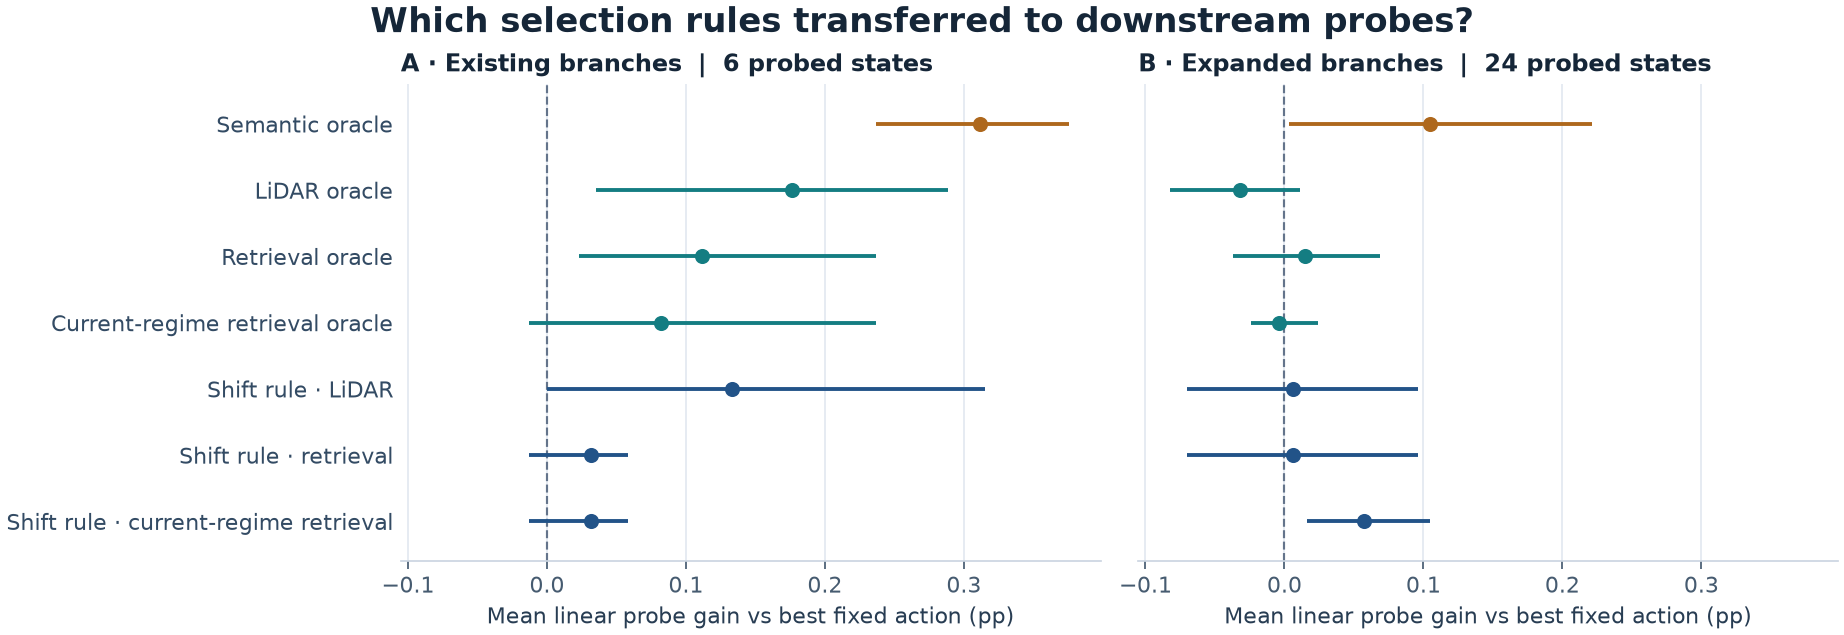

In [ ]:
show_plot(semantic_comparison(stage_a, stage_b))


## Stage B · Where the semantic oracle used more plasticity

Full adaptation was chosen more often on a return to a known regime than after a new regime. These counts describe choices on the probed checkpoints. The right panel shows the task-level changes versus Skip, including kNN readouts from the same selected actions. Those kNN scores were excluded from action selection.

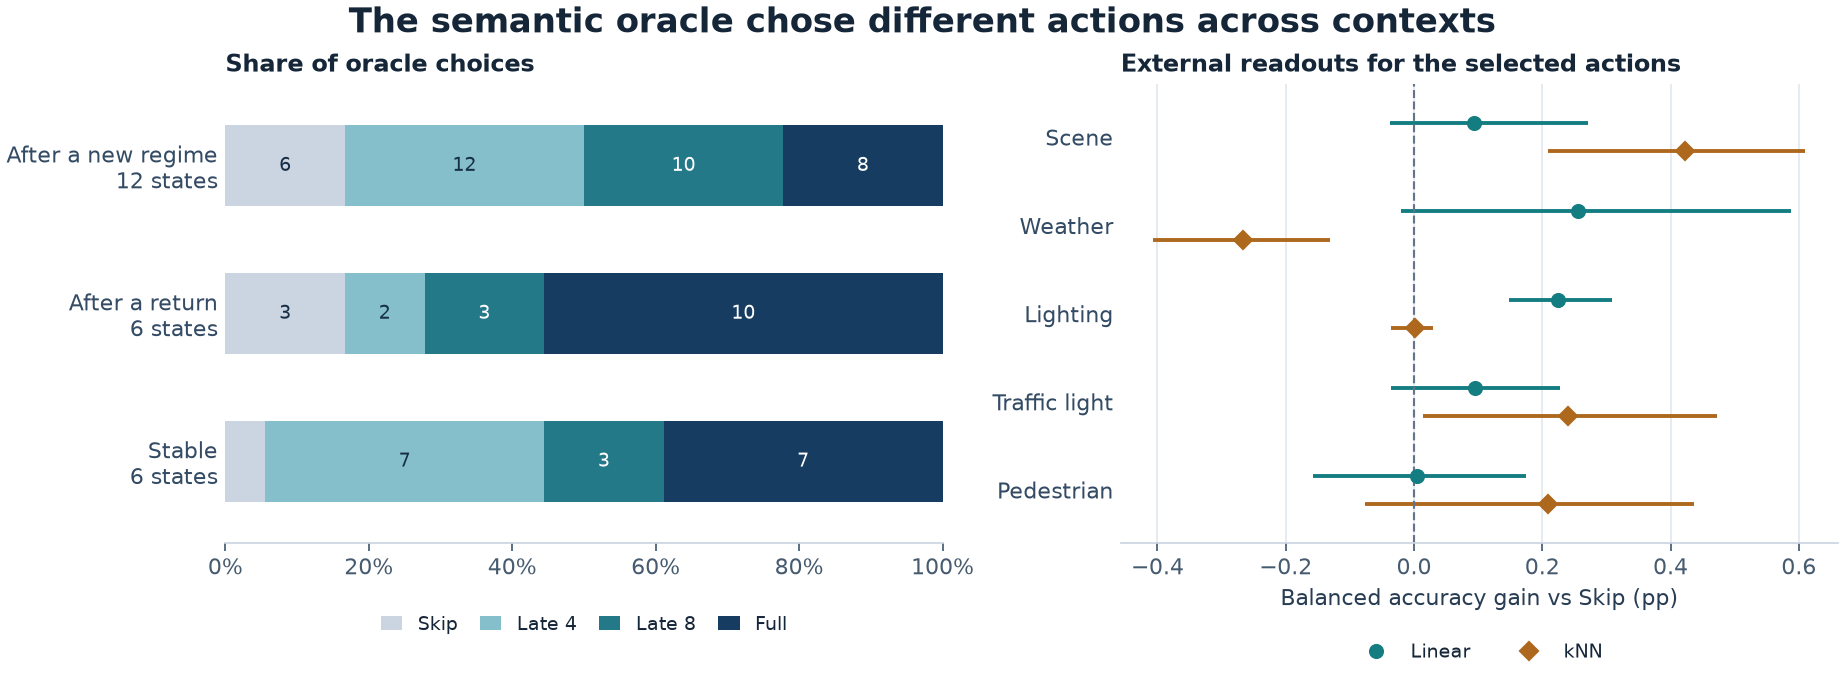

In [ ]:
show_plot(semantic_detail(stage_b))


## Stage C · Are the action effects predictable?

The predictors estimate how each action changes **time-averaged LiDAR** (effective discriminant dimensionality across images and views) or **time-averaged retrieval margin** (same-image similarity minus the hardest other-image similarity). They predict advantages over Skip. Each held-out seed includes all its checkpoints and draws. Ridge regularization is selected inside the training seeds.

**Context** uses training history, novelty and redundancy. **Layer health** adds rank, centered rank, CKA drift, MMD² and retrieval by layer. **Update-aware** also uses trial loss, gradients and optimizer-update magnitudes. The fixed-action baseline estimates constant advantages from the training seeds.

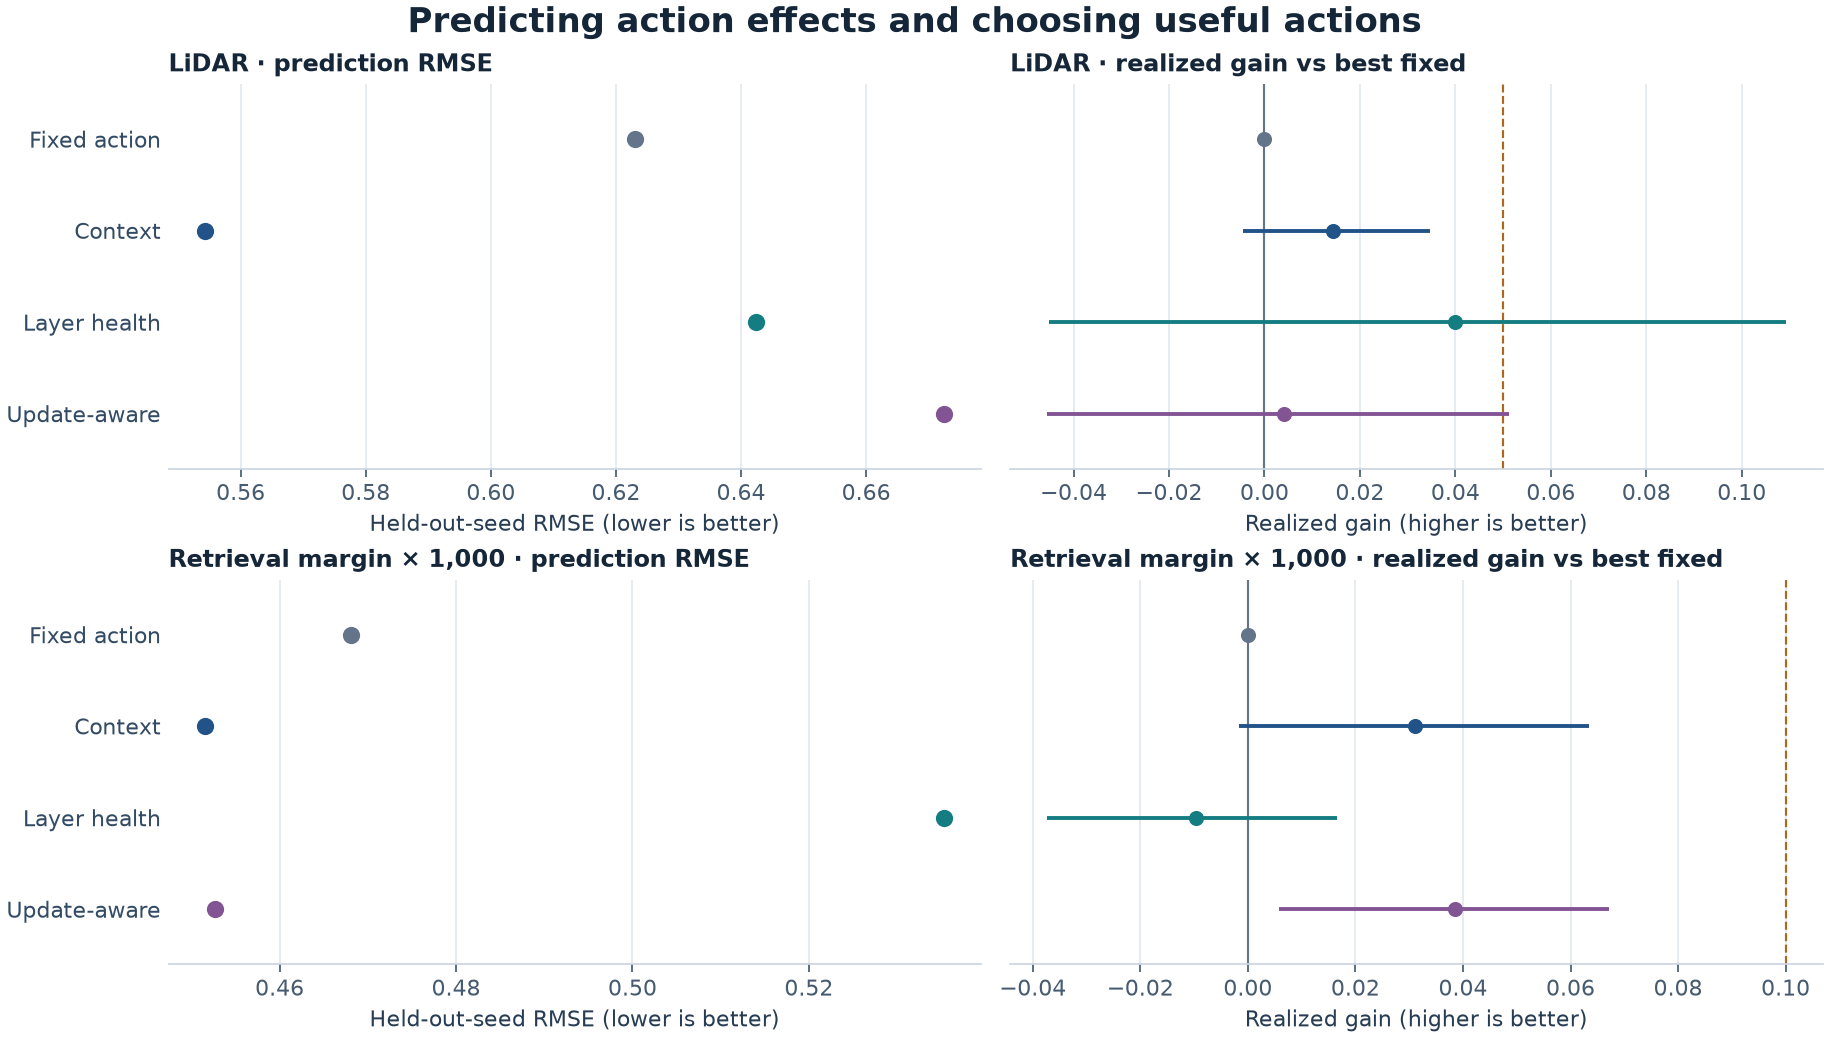

In [ ]:
show_plot(predictor_comparison(predictors))


The dashed line marks the minimum mean gain over fixed. The gate also requires the same minimum over Context and a positive lower seed-bootstrap bound on both comparisons.

- **LiDAR.** Layer health gained **+0.040 [-0.045, +0.109]** over fixed and **+0.026 [-0.078, +0.103]** over Context. Context had the lowest LiDAR prediction RMSE.
- **Retrieval margin.** Update-aware gained **+0.039 [+0.006, +0.067]** over fixed and **+0.007 [-0.018, +0.035]** over Context, in margin × 1,000 units. The required gain was **+0.100** in those units.

The best fixed comparator in Stage C is selected on the **unlabeled** training objective. The downstream scores below are external checks.

### LiDAR units

| Predictor | Inputs | RMSE | Gain vs fixed | Gain vs Context | Probe gain vs Skip (pp) | Choices¹ |
| --- | --- | --- | --- | --- | --- | --- |
| Fixed action | — | 0.623 | +0.000 [+0.000, +0.000] | — | +0.000 [+0.000, +0.000] | 144 / 0 / 0 / 0 |
| Context | 8 | 0.554 | +0.014 [-0.004, +0.035] | — | -0.001 [-0.064, +0.041] | 120 / 15 / 9 / 0 |
| Layer health | 68 | 0.642 | +0.040 [-0.045, +0.109] | +0.026 [-0.078, +0.103] | +0.038 [+0.019, +0.060] | 81 / 39 / 18 / 6 |
| Update-aware | 94 | 0.672 | +0.004 [-0.046, +0.051] | -0.010 [-0.074, +0.042] | +0.049 [+0.025, +0.074] | 81 / 39 / 15 / 9 |

### Retrieval margin × 1,000

| Predictor | Inputs | RMSE | Gain vs fixed | Gain vs Context | Probe gain vs Skip (pp) | Choices¹ |
| --- | --- | --- | --- | --- | --- | --- |
| Fixed action | — | 0.468 | +0.000 [+0.000, +0.000] | — | +0.087 [-0.017, +0.169] | 0 / 144 / 0 / 0 |
| Context | 8 | 0.452 | +0.031 [-0.002, +0.063] | — | +0.072 [+0.024, +0.126] | 45 / 99 / 0 / 0 |
| Layer health | 68 | 0.535 | -0.010 [-0.037, +0.017] | -0.041 [-0.066, -0.017] | +0.033 [-0.007, +0.074] | 54 / 84 / 0 / 6 |
| Update-aware | 94 | 0.453 | +0.039 [+0.006, +0.067] | +0.007 [-0.018, +0.035] | +0.057 [+0.028, +0.086] | 51 / 93 / 0 / 0 |

¹ Choices are scored draw counts in the order **Skip / Late 4 / Late 8 / Full**. Stage C makes one choice per state and scores it on all three draws. Its probe results cover the 24 probed states.

### Stage A · Training cost and choices

| Rule | Probe gain vs Skip (pp) | Training seconds | Gain (pp/s) | Choices¹ |
| --- | --- | --- | --- | --- |
| Semantic oracle | +0.178 [+0.060, +0.322] | 9.44 | +0.0189 | 6 / 3 / 3 / 6 |
| LiDAR oracle | +0.043 [-0.027, +0.122] | 6.70 | +0.0065 | 9 / 4 / 3 / 2 |
| Retrieval oracle | -0.022 [-0.240, +0.153] | 9.13 | -0.0024 | 3 / 11 / 4 / 0 |
| Current-regime retrieval oracle | -0.051 [-0.328, +0.153] | 8.45 | -0.0060 | 3 / 14 / 1 / 0 |
| Shift rule · LiDAR | +0.000 [+0.000, +0.000] | 0.00 | — | 18 / 0 / 0 / 0 |
| Shift rule · retrieval | -0.101 [-0.328, +0.058] | 9.80 | -0.0103 | 0 / 18 / 0 / 0 |
| Shift rule · current-regime retrieval | -0.101 [-0.328, +0.058] | 9.80 | -0.0103 | 0 / 18 / 0 / 0 |

### Stage B · Training cost and choices

| Rule | Probe gain vs Skip (pp) | Training seconds | Gain (pp/s) | Choices¹ |
| --- | --- | --- | --- | --- |
| Semantic oracle | +0.135 [+0.037, +0.233] | 11.90 | +0.0113 | 10 / 21 / 16 / 25 |
| LiDAR oracle | -0.002 [-0.095, +0.064] | 5.84 | -0.0003 | 35 / 25 / 7 / 5 |
| Retrieval oracle | +0.044 [-0.027, +0.107] | 6.81 | +0.0065 | 29 / 30 / 8 / 5 |
| Current-regime retrieval oracle | +0.026 [-0.102, +0.117] | 9.59 | +0.0027 | 15 / 36 / 7 / 14 |
| Shift rule · LiDAR | +0.036 [+0.002, +0.074] | 2.89 | +0.0125 | 51 / 21 / 0 / 0 |
| Shift rule · retrieval | +0.036 [+0.002, +0.074] | 2.89 | +0.0125 | 51 / 21 / 0 / 0 |
| Shift rule · current-regime retrieval | +0.087 [-0.017, +0.169] | 9.70 | +0.0090 | 0 / 72 / 0 / 0 |

## Scope and source data

- Stage A’s semantic reads cover checkpoints just after a new or returning regime. Stage B adds probed stable checkpoints.
- Training seconds exclude monitoring and probe overhead. Skip has zero training time, so its gain per training second is undefined.
- Development results use six source seeds. Seeds 7–9 are reserved for prospective confirmation. The analysis evaluates branch choices and does not measure a deployed controller.

The frozen design, per-seed bootstrap summaries, task scores, fold details, raw branches and feature vectors are available in `C:\CAFL-E\analysis\2026-11-09-one-step-mpc\o3-simsiam-control\e204`. The charts and tables use `stage-a-analysis.json`, `stage-b-analysis.json`, and `predictor-summary.json`.